# Dataset for people with Car/Van Accessibility across England

In [48]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df0= pd.read_excel("Car_or_Van_access.xlsx")
print("Dataset shape:", df.shape)
df0 = df0.rename(columns={"Lower layer Super Output Areas Code": "LSOA_code"})
df0.head()


Dataset shape: (1236, 5)


,LSOA_code,Lower layer Super Output Areas,Car or van availability (5 categories) Code,Car or van availability (5 categories),Observation
0,E01000001,City of London 001A,-8,Does not apply,0
1,E01000001,City of London 001A,0,No cars or vans in household,555
2,E01000001,City of London 001A,1,1 car or van in household,243
3,E01000001,City of London 001A,2,2 cars or vans in household,29
4,E01000001,City of London 001A,3,3 or more cars or vans in household,10


In [54]:
df0.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 176034 entries, 0 to 176033
Data columns (total 5 columns):
 #   Column                                       Non-Null Count   Dtype 
---  ------                                       --------------   ----- 
 0   LSOA_code                                    176034 non-null  object
 1   Lower layer Super Output Areas               176034 non-null  object
 2   Car or van availability (5 categories) Code  176034 non-null  int64 
 3   Car or van availability (5 categories)       176034 non-null  object
 4   Observation                                  176034 non-null  int64 
dtypes: int64(2), object(3)
memory usage: 6.7+ MB


In [55]:
#Remove the rows for Wales
df = df0[~df0["LSOA_code"].str.startswith("W")]
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 168775 entries, 0 to 168774
Data columns (total 5 columns):
 #   Column                                       Non-Null Count   Dtype 
---  ------                                       --------------   ----- 
 0   LSOA_code                                    168775 non-null  object
 1   Lower layer Super Output Areas               168775 non-null  object
 2   Car or van availability (5 categories) Code  168775 non-null  int64 
 3   Car or van availability (5 categories)       168775 non-null  object
 4   Observation                                  168775 non-null  int64 
dtypes: int64(2), object(3)
memory usage: 7.7+ MB


In [56]:
#removes all leading and trailing whitespace from the column names
df.columns = df.columns.str.strip()

In [57]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicates:", df.duplicated().sum())
print("Unique LSOAs:", df["LSOA_code"].nunique())

Missing values: 0
Duplicates: 0
Unique LSOAs: 33755


# Data Cleaning

In [58]:
# Remove exact duplicate rows
df = df.drop_duplicates().copy()
# Remove 'Does not apply' category
df = df[
    df["Car or van availability (5 categories)"] != "Does not apply"
].copy()

In [59]:
# Updated Categories
print(
    df["Car or van availability (5 categories)"]
    .value_counts()
)

Car or van availability (5 categories)
No cars or vans in household           33755
1 car or van in household              33755
2 cars or vans in household            33755
3 or more cars or vans in household    33755
Name: count, dtype: int64


In [60]:
print("\nFinal shape:", df.shape)


Final shape: (135020, 5)


In [61]:
print(df["Observation"].describe())

# Check for impossible negative household counts
print("Negative observations:", (df["Observation"] < 0).sum())

count    135020.000000
mean        173.573093
std         117.708472
min           0.000000
25%          72.000000
50%         159.000000
75%         256.000000
max        1025.000000
Name: Observation, dtype: float64
Negative observations: 0


A zero can legitimately mean that no households in an LSOA belong to that category.

In [62]:
car_wide = df.pivot_table(
    index="LSOA_code",
    columns="Car or van availability (5 categories)",
    values="Observation",
    aggfunc="sum",
    fill_value=0
).reset_index()

car_wide.head()

Car or van availability (5 categories),LSOA_code,1 car or van in household,2 cars or vans in household,3 or more cars or vans in household,No cars or vans in household
0,E01000001,243,29,10,555
1,E01000002,208,26,12,578
2,E01000003,169,15,7,826
3,E01000005,92,9,3,375
4,E01000006,251,95,25,183


In [63]:
print(car_wide.shape)
print(car_wide.columns.tolist())

(33755, 5)
['LSOA_code', '1 car or van in household', '2 cars or vans in household', '3 or more cars or vans in household', 'No cars or vans in household']


# Feature Engineering

Total households across each LSOA(region)

In [ ]:
car_wide["Total_households"] = (
    car_wide["No cars or vans in household"]
    + car_wide["1 car or van in household"]
    + car_wide["2 cars or vans in household"]
    + car_wide["3 or more cars or vans in household"]
)

Percentage of households without a car

In [ ]:
car_wide["No_car_pct"] = np.where(
    car_wide["Total_households"] > 0,
    (
        car_wide["No cars or vans in household"]
        / car_wide["Total_households"]
    ) * 100,
    np.nan
)

Percentage with at least one car

In [ ]:
car_wide["Car_access_pct"] = np.where(
    car_wide["Total_households"] > 0,
    (
        car_wide["1 car or van in household"]
        + car_wide["2 cars or vans in household"]
        + car_wide["3 or more cars or vans in household"]
    )
    / car_wide["Total_households"] * 100,
    np.nan
)

In [76]:
print(
    car_wide[
        ["Total_households",
         "No_car_pct",
         "Car_access_pct"]
    ].describe()
)

Car or van availability (5 categories)  Total_households    No_car_pct  \
count                                       33755.000000  33755.000000   
mean                                          694.292372     23.092617   
std                                           143.465756     15.892282   
min                                           398.000000      0.418410   
25%                                           601.000000     10.589024   
50%                                           665.000000     18.810289   
75%                                           766.000000     31.656623   
max                                          1547.000000     89.760000   

Car or van availability (5 categories)  Car_access_pct  
count                                     33755.000000  
mean                                         76.907383  
std                                          15.892282  
min                                          10.240000  
25%                                          68.

0        100.0
1        100.0
2        100.0
3        100.0
4        100.0
         ...  
33750    100.0
33751    100.0
33752    100.0
33753    100.0
33754    100.0
Length: 33755, dtype: float64

this is to check if its 100% for each valid LSOA. Temporary check

car_wide["Percentage_check"] = (
    car_wide["No_car_pct"]
    + car_wide["Car_access_pct"]
)

car_wide["Percentage_check"].head()


# EDA

## Distribution of No Car households

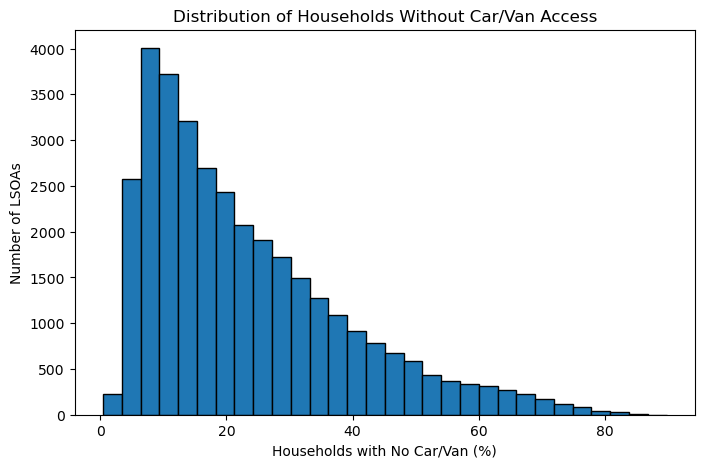

In [69]:
plt.figure(figsize=(8, 5))

plt.hist(
    car_wide["No_car_pct"].dropna(),
    bins=30,
    edgecolor="black"
)

plt.xlabel("Households with No Car/Van (%)")
plt.ylabel("Number of LSOAs")
plt.title("Distribution of Households Without Car/Van Access")

plt.show()

The above graph indicates a right-skewed distribution: Most Lower Layer Super Output Areas (LSOAs) have a low percentage of households without car or van access, peaking around 8%–12%. The vast majority of areas fall below 30% non-ownership, showing that car/van availability is high across most regions.
**Outlier Tail**: A small number of LSOAs have high non-ownership rates stretching up to 80%+, likely representing dense urban centers with robust public transit or lower average incomes.

Identify high no-car-access region(LSOAs)

In [ ]:
car_wide.sort_values("No_car_pct",ascending=False)[["LSOA_code", "No_car_pct"]].head(10)

Car or van availability (5 categories),LSOA_code,No_car_pct
31915,E01033874,89.760000
31767,E01033711,86.833144
33681,E01035688,86.167147
897,E01000937,85.885167
818,E01000855,85.555556
31764,E01033708,85.272145
32258,E01034220,84.415584
31907,E01033866,84.134615
817,E01000853,83.888889
4481,E01004735,83.448873


In [ ]:
# Correlation Matrix
features = ["No_car_pct", "Car_access_pct", "Total_households"]
correlation = car_wide[features].corr()
print(correlation)

Car or van availability (5 categories)  No_car_pct  Car_access_pct  \
Car or van availability (5 categories)                               
No_car_pct                                1.000000       -1.000000   
Car_access_pct                           -1.000000        1.000000   
Total_households                          0.135136       -0.135136   

Car or van availability (5 categories)  Total_households  
Car or van availability (5 categories)                    
No_car_pct                                      0.135136  
Car_access_pct                                 -0.135136  
Total_households                                1.000000  


In [72]:
car_features = car_wide[
    [
        "LSOA_code",
        "No_car_pct"
    ]
].copy()

car_features.head()

Car or van availability (5 categories),LSOA_code,No_car_pct
0,E01000001,66.308244
1,E01000002,70.145631
2,E01000003,81.219272
3,E01000005,78.288100
4,E01000006,33.032491


'Car_access_pct=100−No_car_pct'  

It is not included in final ML feature as its complement to the feature No_car_pct that represents that percentage of households acrss England with no car.

In [ ]:
print("Rows:", len(car_features))
print("Unique LSOAs:", car_features["LSOA_code"].nunique())
print("Missing values:")
print(car_features.isnull().sum())

Rows: 33755
Unique LSOAs: 33755
Missing values:
Car or van availability (5 categories)
LSOA_code     0
No_car_pct    0
dtype: int64


In [ ]:
car_features.to_excel(
    "car_availability_features_LSOA.xlsx",
    index=False
)

A new dataset with selected relevant features have been created which will used to form an integrated dataset in Master Notebook